In [ ]:
# Cell 1 — Imports, figure inputs, and common plotting settings
#
# Purpose:
# Generate publication figures from the saved reconstruction
# and evaluation results.

from pathlib import Path
import gzip
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize


# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------

def find_project_root(start=None):
    start_path = Path.cwd() if start is None else Path(start)
    start_path = start_path.resolve()

    for directory in (start_path, *start_path.parents):
        if (
            (directory / "README.md").is_file()
            and (directory / "notebooks").is_dir()
            and (directory / "data").is_dir()
        ):
            return directory

    raise FileNotFoundError(
        "Run this notebook from within the repository containing "
        "README.md, notebooks/, and data/."
    )


PROJECT_ROOT = find_project_root()


def project_relative(path):
    return Path(path).relative_to(PROJECT_ROOT).as_posix()

SAMPLE_NAME = "p28_330_HET_009"

EVALUATION_DIR = (
    PROJECT_ROOT / "results" / SAMPLE_NAME / "08_evaluation"
)

FIGURE_DIR = (
    PROJECT_ROOT / "results" / SAMPLE_NAME / "09_figures"
)

evaluation_info_file = EVALUATION_DIR / "evaluation_info.json"

if not evaluation_info_file.is_file():
    raise FileNotFoundError(
        f"Evaluation record not found: {project_relative(evaluation_info_file)}"
    )

evaluation_info = json.loads(
    evaluation_info_file.read_text(encoding="utf-8")
)

source_run_info_file = (
    EVALUATION_DIR
    / evaluation_info["files"]["source_run_info"]
)

run_info = json.loads(
    source_run_info_file.read_text(encoding="utf-8")
)

if (
    evaluation_info["sample"] != SAMPLE_NAME
    or run_info["sample"] != SAMPLE_NAME
):
    raise ValueError("The saved records do not match SAMPLE_NAME.")

RECONSTRUCTION_DIR = PROJECT_ROOT / Path(
    evaluation_info["reconstruction_directory"]
)

# Check that Step07 has not been replaced since evaluation.
current_run_info = json.loads(
    (RECONSTRUCTION_DIR / "run_info.json").read_text(
        encoding="utf-8"
    )
)

if current_run_info != run_info:
    raise RuntimeError(
        "The Step07 run record has changed since evaluation. "
        "Update Step08 before generating the figures."
    )


# --------------------------------------------------
# 2. Locate the saved figure inputs
# --------------------------------------------------

RECONSTRUCTION_FILES = {
    name: RECONSTRUCTION_DIR / run_info["files"][name]
    for name in [
        "normalized_raw_mip",
        "soma_target",
        "final_mask",
        "adjusted_score",
        "hitting_probability",
    ]
}

EVALUATION_FILES = {
    name: EVALUATION_DIR / evaluation_info["files"][name]
    for name in [
        "roi_metadata",
        "manual_trace_voxels",
        "coverage_table",
        "correction_comparison",
        "inverse_L_score",
    ]
}

COMPARISON_MASK_FILES = {
    name: EVALUATION_DIR / filename
    for name, filename
    in evaluation_info["correction_mask_files"].items()
}

TRACE_FILE = PROJECT_ROOT / evaluation_info["manual_trace_source"]

required_paths = [
    *RECONSTRUCTION_FILES.values(),
    *EVALUATION_FILES.values(),
    *COMPARISON_MASK_FILES.values(),
    TRACE_FILE,
]

missing_files = [
    project_relative(path) for path in required_paths if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Missing figure inputs:\n" + "\n".join(missing_files)
    )


# --------------------------------------------------
# 3. Common plotting settings
# --------------------------------------------------

FONT_SIZE = 9
EXPORT_DPI = 300
EXPORT_FORMATS = ("png",)
SCORE_CMAP = "plasma"

SCORE_THRESHOLD = float(
    evaluation_info["matched_filtering"]["score_threshold"]
)

SCORE_NORM = Normalize(
    vmin=SCORE_THRESHOLD,
    vmax=1.0,
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": EXPORT_DPI,
})

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Sample: {SAMPLE_NAME}")
print(f"Reconstruction source: {project_relative(RECONSTRUCTION_DIR)}")
print(f"Evaluation source: {project_relative(EVALUATION_DIR)}")
print(f"Figure directory: {project_relative(FIGURE_DIR)}")
print(f"Export formats: {', '.join(EXPORT_FORMATS)}")

In [3]:
# Cell 2 — Load plotting data and prepare the XY projections

# --------------------------------------------------
# 1. Open the reconstruction arrays
# --------------------------------------------------

reconstruction_arrays = {
    name: np.load(
        path,
        mmap_mode="r",
        allow_pickle=False,
    )
    for name, path in RECONSTRUCTION_FILES.items()
}

normalized_intensity_yx = reconstruction_arrays["normalized_raw_mip"]
target_zyx = reconstruction_arrays["soma_target"]
final_mask_zyx = reconstruction_arrays["final_mask"]

P_hit_zyx = reconstruction_arrays["hitting_probability"]
sqrtL_score_zyx = reconstruction_arrays["adjusted_score"]

score_inverse_L_zyx = np.load(
    EVALUATION_FILES["inverse_L_score"],
    mmap_mode="r",
    allow_pickle=False,
)

comparison_masks_zyx = {
    name: np.load(
        path,
        mmap_mode="r",
        allow_pickle=False,
    )
    for name, path in COMPARISON_MASK_FILES.items()
}

score_arrays_zyx = {
    "uncorrected": P_hit_zyx,
    "inverse_L": score_inverse_L_zyx,
    "inverse_sqrtL": sqrtL_score_zyx,
}


# --------------------------------------------------
# 2. Read the metadata and evaluation tables
# --------------------------------------------------

metadata_table = pd.read_csv(EVALUATION_FILES["roi_metadata"])

if len(metadata_table) != 1:
    raise ValueError("Expected one row of ROI metadata.")

metadata = metadata_table.iloc[0]

roi_x0 = int(metadata["global_x0_zero_based"])
roi_y0 = int(metadata["global_y0_zero_based"])

shape_zyx = tuple(int(n) for n in run_info["shape_zyx"])
shape_yx = shape_zyx[1:]

coverage_summary = pd.read_csv(
    EVALUATION_FILES["coverage_table"]
)

correction_comparison_table = pd.read_csv(
    EVALUATION_FILES["correction_comparison"]
)


# --------------------------------------------------
# 3. Check the plotting inputs
# --------------------------------------------------

assert normalized_intensity_yx.shape == shape_yx
assert target_zyx.shape == shape_zyx
assert final_mask_zyx.shape == shape_zyx

for name, score_zyx in score_arrays_zyx.items():
    assert score_zyx.shape == shape_zyx, name
    assert comparison_masks_zyx[name].shape == shape_zyx, name
    assert comparison_masks_zyx[name].dtype == np.dtype(bool), name

if not np.array_equal(
    comparison_masks_zyx["inverse_sqrtL"],
    final_mask_zyx,
):
    raise ValueError(
        "The comparison baseline differs from the saved final mask."
    )


# --------------------------------------------------
# 4. Prepare the target and score projections
# --------------------------------------------------

target_mip_yx = target_zyx.any(axis=0)

comparison_mask_mips_yx = {}
score_displays_yx = {}

for name, score_zyx in score_arrays_zyx.items():
    mask_zyx = comparison_masks_zyx[name]
    mask_mip_yx = mask_zyx.any(axis=0)

    # Take the maximum score over assigned voxels only.
    selected_score_yx = np.max(
        np.where(mask_zyx, score_zyx, 0.0),
        axis=0,
    )

    comparison_mask_mips_yx[name] = mask_mip_yx

    score_displays_yx[name] = np.ma.masked_where(
        ~mask_mip_yx,
        selected_score_yx,
    )

final_score_display_yx = score_displays_yx["inverse_sqrtL"]

print(f"Image shape (Y, X): {shape_yx}")
print(f"ROI origin (global X, Y): ({roi_x0}, {roi_y0})")
print(f"Prepared score projections: {list(score_displays_yx)}")

print(
    "\nSaved coverage results:\n"
    + coverage_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)

Image shape (Y, X): (241, 241)
ROI origin (global X, Y): (742, 433)
Prepared score projections: ['uncorrected', 'inverse_L', 'inverse_sqrtL']

Saved coverage results:
                    evaluation  manual_locations  covered_locations  missed_locations  coverage_percent
          3D exact, within ROI              2491               2092               399             83.98
XY projected exact, within ROI              2399               2099               300             87.49


In [4]:
# Cell 3 — Prepare the manual-tracing overlay

# --------------------------------------------------
# 1. Read the original tracing file
# --------------------------------------------------

with TRACE_FILE.open("rb") as file:
    is_gzipped = file.read(2) == b"\x1f\x8b"

trace_open = gzip.open if is_gzipped else open

with trace_open(TRACE_FILE, "rt", encoding="utf-8") as file:
    trace_root = ET.parse(file).getroot()


# --------------------------------------------------
# 2. Convert each path to local XY coordinates
# --------------------------------------------------

manual_trace_segments = []

for path_node in trace_root.findall(".//path"):
    points_xy = np.asarray(
        [
            [
                float(point.attrib["x"]) - roi_x0,
                float(point.attrib["y"]) - roi_y0,
            ]
            for point in path_node.findall("./point")
        ],
        dtype=np.float64,
    )

    if len(points_xy) == 0:
        continue

    if not np.isfinite(points_xy).all():
        raise ValueError("The tracing contains non-finite coordinates.")

    # Keep each path separate, including its out-of-ROI vertices.
    # The plotting axes will clip paths at the image boundary.
    manual_trace_segments.append(points_xy)

if not manual_trace_segments:
    raise ValueError("No manual-tracing paths were found.")

point_count = sum(len(points) for points in manual_trace_segments)

if (
    len(manual_trace_segments)
    != evaluation_info["trace"]["path_count"]
    or point_count
    != evaluation_info["trace"]["control_point_count"]
):
    raise ValueError(
        "Tracing path or point counts differ from the evaluation record. "
        "Check the tracing source before plotting."
    )


# --------------------------------------------------
# 3. Define the tracing overlay
# --------------------------------------------------

def draw_manual_tracing(
    ax,
    color="cyan",
    linewidth=0.7,
    outline_width=1.4,
):
    for points in manual_trace_segments:
        marker = "o" if len(points) == 1 else None

        ax.plot(
            points[:, 0],
            points[:, 1],
            color="black",
            linewidth=outline_width,
            marker=marker,
            markersize=2.0,
            clip_on=True,
        )

        ax.plot(
            points[:, 0],
            points[:, 1],
            color=color,
            linewidth=linewidth,
            marker=marker,
            markersize=1.0,
            clip_on=True,
        )


# --------------------------------------------------
# 4. Define a common image-axis format
# --------------------------------------------------

def format_image_axis(ax):
    ny, nx = shape_yx

    ax.set_xlim(-0.5, nx - 0.5)
    ax.set_ylim(ny - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_axis_off()


print(f"Manual-tracing paths: {len(manual_trace_segments):,}")
print(f"Tracing control points: {point_count:,}")
print("Tracing overlay and image-axis helpers are ready.")

Manual-tracing paths: 125
Tracing control points: 2,884
Tracing overlay and image-axis helpers are ready.


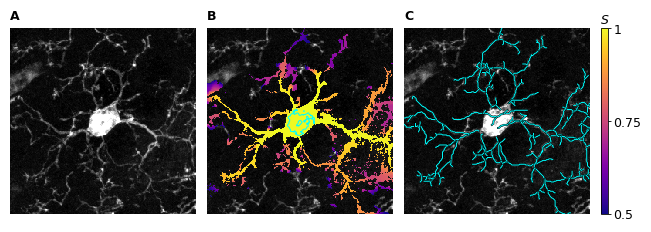

In [ ]:
# Cell 4 — Draw and export the combined reconstruction figure

# --------------------------------------------------
# 1. Define shared drawing and export helpers
# --------------------------------------------------

score_cmap = plt.get_cmap(SCORE_CMAP).copy()
score_cmap.set_bad(alpha=0.0)


def draw_image_panel(ax, kind, score_display=None):
    ax.imshow(
        normalized_intensity_yx,
        cmap="gray",
        vmin=0,
        vmax=1,
        origin="upper",
        interpolation="nearest",
    )

    score_image = None

    if kind == "reconstruction":
        if score_display is None:
            score_display = final_score_display_yx

        score_image = ax.imshow(
            score_display,
            cmap=score_cmap,
            norm=SCORE_NORM,
            origin="upper",
            interpolation="nearest",
        )

        ax.contour(
            target_mip_yx,
            levels=[0.5],
            colors=["cyan"],
            linewidths=0.7,
        )

    elif kind == "tracing":
        draw_manual_tracing(ax)

    elif kind != "raw":
        raise ValueError(f"Unknown panel kind: {kind}")

    format_image_axis(ax)
    return score_image


def add_score_colorbar(fig, cax, score_image):
    colorbar = fig.colorbar(
        score_image,
        cax=cax,
        ticks=np.linspace(SCORE_THRESHOLD, 1.0, 3),
        format="%.2g",
    )

    colorbar.ax.set_title(
        r"$S$",
        fontsize=FONT_SIZE,
        pad=3,
    )

    colorbar.ax.tick_params(
        labelsize=FONT_SIZE,
        length=2,
        width=0.6,
        pad=2,
    )

    colorbar.outline.set_linewidth(0.6)


def save_publication_figure(fig, stem):
    saved_files = {}

    # Preserve the canvas size instead of cropping panels differently.
    with plt.rc_context({"savefig.bbox": None}):
        for extension in EXPORT_FORMATS:
            filename = f"{stem}.{extension}"

            fig.savefig(
                FIGURE_DIR / filename,
                dpi=EXPORT_DPI,
                facecolor="white",
                bbox_inches=None,
            )

            saved_files[extension] = filename

    return saved_files


# --------------------------------------------------
# 2. Draw the combined three-panel figure
# --------------------------------------------------

panel_definitions = [
    ("A", "raw"),
    ("B", "reconstruction"),
    ("C", "tracing"),
]

figure_outputs = {}

fig = plt.figure(figsize=(6.5, 2.4))

grid = fig.add_gridspec(
    1,
    4,
    width_ratios=[1, 1, 1, 0.035],
    left=0.01,
    right=0.93,
    bottom=0.06,
    top=0.86,
    wspace=0.08,
)

axes = [fig.add_subplot(grid[0, i]) for i in range(3)]
colorbar_ax = fig.add_subplot(grid[0, 3])

for ax, (letter, kind) in zip(axes, panel_definitions):
    score_image = draw_image_panel(ax, kind)

    if kind == "reconstruction":
        reconstruction_image = score_image

    ax.text(
        0.0,
        1.03,
        letter,
        transform=ax.transAxes,
        fontsize=FONT_SIZE,
        fontweight="bold",
        ha="left",
        va="bottom",
    )

# Align the colorbar with the image area.
fig.canvas.draw()

image_position = axes[1].get_position()
bar_position = colorbar_ax.get_position()

colorbar_ax.set_position([
    bar_position.x0,
    image_position.y0,
    bar_position.width,
    image_position.height,
])

add_score_colorbar(fig, colorbar_ax, reconstruction_image)

figure_outputs["reconstruction_panels"] = save_publication_figure(
    fig,
    "p28_reconstruction_panels",
)

plt.show()
plt.close(fig)


print("Saved the combined reconstruction figure.")
print(f"Figure directory: {project_relative(FIGURE_DIR)}")

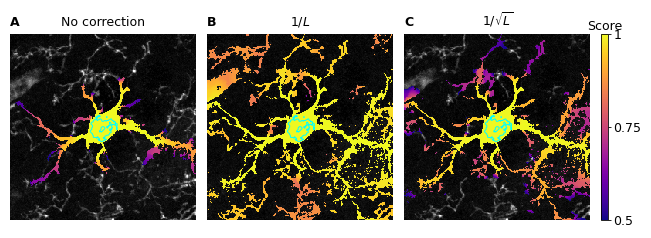

      version  coverage_3d_percent  coverage_xy_percent  selected_3d_voxels
  uncorrected                35.33                37.31               81621
    inverse_L                90.57                90.29              441521
inverse_sqrtL                83.98                87.49              233435

Comparison figures saved to: results/p28_330_HET_009/09_figures


In [6]:
# Cell 5 — Draw the three correction methods with matched display settings

# --------------------------------------------------
# 1. Define panel order and labels
# --------------------------------------------------

correction_panels = [
    ("uncorrected", "A", "No correction"),
    ("inverse_L", "B", r"$1/L$"),
    ("inverse_sqrtL", "C", r"$1/\sqrt{L}$"),
]


# --------------------------------------------------
# 2. Draw the combined comparison figure
# --------------------------------------------------

fig = plt.figure(figsize=(6.5, 2.4))

grid = fig.add_gridspec(
    1,
    4,
    width_ratios=[1, 1, 1, 0.035],
    left=0.01,
    right=0.93,
    bottom=0.06,
    top=0.86,
    wspace=0.08,
)

axes = [fig.add_subplot(grid[0, i]) for i in range(3)]
colorbar_ax = fig.add_subplot(grid[0, 3])

for ax, (name, letter, label) in zip(axes, correction_panels):
    score_image = draw_image_panel(
        ax,
        "reconstruction",
        score_display=score_displays_yx[name],
    )

    ax.text(
        0.0,
        1.03,
        letter,
        transform=ax.transAxes,
        fontsize=FONT_SIZE,
        fontweight="bold",
        ha="left",
        va="bottom",
    )

    ax.text(
        0.5,
        1.03,
        label,
        transform=ax.transAxes,
        fontsize=FONT_SIZE,
        ha="center",
        va="bottom",
    )

# Align the shared colorbar with the image area.
fig.canvas.draw()

image_position = axes[1].get_position()
bar_position = colorbar_ax.get_position()

colorbar_ax.set_position([
    bar_position.x0,
    image_position.y0,
    bar_position.width,
    image_position.height,
])

add_score_colorbar(fig, colorbar_ax, score_image)

# A generic label applies to all three score definitions.
colorbar_ax.set_title(
    "Score",
    fontsize=FONT_SIZE,
    pad=3,
)

figure_outputs["correction_comparison"] = save_publication_figure(
    fig,
    "three_correction_maps",
)

plt.show()
plt.close(fig)


# --------------------------------------------------
# 3. Display the saved quantitative comparison
# --------------------------------------------------

panel_order = [
    name for name, _, _ in correction_panels
]

display_table = (
    correction_comparison_table
    .set_index("version")
    .loc[
        panel_order,
        [
            "coverage_3d_percent",
            "coverage_xy_percent",
            "selected_3d_voxels",
        ],
    ]
    .reset_index()
)

print(
    display_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)

print(f"\nComparison figures saved to: {project_relative(FIGURE_DIR)}")

In [ ]:
# Cell 6 — Save figure provenance and the output manifest

import matplotlib


# --------------------------------------------------
# 1. Check the expected figure groups
# --------------------------------------------------

expected_groups = {
    "reconstruction_panels",
    "correction_comparison",
}

missing_groups = expected_groups - set(figure_outputs)

if missing_groups:
    raise RuntimeError(
        "Missing figure groups: "
        + ", ".join(sorted(missing_groups))
        + ". Run Cells 4 and 5 before saving the manifest."
    )

missing_files = []

for group in sorted(expected_groups):
    for extension in EXPORT_FORMATS:
        filename = figure_outputs[group].get(extension)

        if filename is None:
            missing_files.append(f"{group}: {extension} export")
        else:
            path = FIGURE_DIR / filename

            if not path.is_file() or path.stat().st_size == 0:
                missing_files.append(project_relative(path))

if missing_files:
    raise FileNotFoundError(
        "Missing or empty figure exports:\n"
        + "\n".join(missing_files)
    )


# --------------------------------------------------
# 2. Preserve the source records and quantitative tables
# --------------------------------------------------

(FIGURE_DIR / "source_reconstruction_run_info.json").write_text(
    json.dumps(run_info, indent=2),
    encoding="utf-8",
)

(FIGURE_DIR / "source_evaluation_info.json").write_text(
    json.dumps(evaluation_info, indent=2),
    encoding="utf-8",
)

coverage_summary.to_csv(
    FIGURE_DIR / "coverage_summary.csv",
    index=False,
)

correction_comparison_table.to_csv(
    FIGURE_DIR / "correction_comparison.csv",
    index=False,
)


# --------------------------------------------------
# 3. Record the figure sources and plotting settings
# --------------------------------------------------

figure_info = {
    "sample": SAMPLE_NAME,
    "reconstruction_directory": project_relative(RECONSTRUCTION_DIR),
    "evaluation_directory": project_relative(EVALUATION_DIR),
    "manual_trace_source": project_relative(TRACE_FILE),
    "source_records": {
        "reconstruction": "source_reconstruction_run_info.json",
        "evaluation": "source_evaluation_info.json",
    },
    "tables": {
        "coverage": "coverage_summary.csv",
        "correction_comparison": "correction_comparison.csv",
    },
    "figures": figure_outputs,
    "plotting": {
        "font_family": list(plt.rcParams["font.family"]),
        "font_size_pt": float(FONT_SIZE),
        "export_dpi": int(EXPORT_DPI),
        "export_formats": list(EXPORT_FORMATS),
        "score_colormap": SCORE_CMAP,
        "score_color_limits": [
            float(SCORE_NORM.vmin),
            float(SCORE_NORM.vmax),
        ],
        "background": "saved normalized raw-image MIP",
        "score_projection": (
            "maximum score over selected voxels along Z"
        ),
        "manual_tracing": (
            "original floating-point XY paths, clipped to the ROI"
        ),
        "manual_trace_color": "cyan",
        "soma_target_contour_color": "cyan",
    },
    "software": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
    },
}

figure_info_file = FIGURE_DIR / "figure_info.json"

figure_info_file.write_text(
    json.dumps(figure_info, indent=2),
    encoding="utf-8",
)

print(f"Figure groups: {len(expected_groups)}")
print(f"Formats: {', '.join(EXPORT_FORMATS)}")
print(f"Figure directory: {project_relative(FIGURE_DIR)}")
print(f"Figure record: {project_relative(figure_info_file)}")